# Tarea #10. KNN - Clasificación de variedades de frijol (Dataset de 13,611 registros)

**Materia:** Inteligencia Artificial

**Docente:** José Mario Ríos Félix

**Horario:** 6:00 a 7:00 p. m.

**Alumna:** Kitzia Marisol Crespo Hernández

**No. de Control:** C23171148

## Descripción

Este notebook implementa el algoritmo de aprendizaje supervisado K-Nearest
Neighbors (KNN), o K vecinos más cercanos, para clasificar la variedad de
un grano de frijol a partir de 16 características numéricas relacionadas
con su forma, tamaño y dimensiones.

Se utiliza el **Dry Bean Dataset**, disponible en el repositorio UCI,
que contiene **13,611 registros** de granos de frijol fotografiados con
una cámara de alta resolución y clasificados en siete variedades.

El procedimiento consiste en dividir los datos en dos grupos, uno de
entrenamiento y otro de prueba, estandarizar las características con
`StandardScaler` y calcular las distancias euclidianas, es decir, medir
la distancia en línea recta entre dos datos a partir de sus características
para determinar qué tan similares son. Este cálculo se realiza de forma
manual con NumPy y después se implementa el algoritmo KNN con scikit-learn.
Posteriormente, se selecciona el valor óptimo de K mediante validación
cruzada y se evalúa el desempeño del clasificador a través de métricas
de clasificación y una matriz de confusión.

**Fuente del dataset:**
<https://archive.ics.uci.edu/dataset/602/dry+bean+dataset>

**Referencia para la implementación de KNN:**
<https://towardsdatascience.com/k-nearest-neighbor-classifier-explained-a-visual-guide-with-code-examples-for-beginners-a3d85cad00e1/>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix)

# se utiliza la misma semilla para obtener los mismos resultados en cada ejecución
SEMILLA = 42

plt.rcParams.update({"figure.dpi": 110,
                     "axes.spines.top": False,
                     "axes.spines.right": False})

## 1. Cargar los datos

In [2]:
# el dataset se descarga del repositorio UCI con su librería oficial
%pip install -q ucimlrepo

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import os
import ssl

import certifi
from ucimlrepo import fetch_ucirepo

# algunas instalaciones de Windows tienen una raíz vencida en su almacén
# de certificados y la descarga falla. Con esta línea Python valida con
# el paquete certifi, que se mantiene actualizado
ssl._create_default_https_context = (
    lambda *a, **k: ssl.create_default_context(cafile=certifi.where()))

# el 602 es el identificador del Dry Bean Dataset dentro de UCI
RESPALDO = "data/Dry_Bean_Dataset.csv"
try:
    dry_bean = fetch_ucirepo(id=602)
    datos = dry_bean.data.original.copy()
    print("Dataset descargado del repositorio UCI")
except Exception as falla:
    # sin internet se usa la copia local, cuando está disponible
    print("No se pudo descargar del repositorio UCI,", type(falla).__name__)
    if not os.path.exists(RESPALDO):
        raise RuntimeError(
            "Se requiere una conexión a internet para descargar el dataset. "
            "Como alternativa, puede descargarse manualmente desde "
            "https://archive.ics.uci.edu/dataset/602/dry+bean+dataset "
            "y guardarse en la siguiente ruta: " + RESPALDO)
    datos = pd.read_csv(RESPALDO)
    print("Se usó la copia local", RESPALDO)

print("Registros", format(len(datos), ","))
print("Columnas ", len(datos.columns))
print("Nulos    ", int(datos.isna().sum().sum()))
datos.head()

Dataset descargado del repositorio UCI
Registros 13,611
Columnas  17
Nulos     0


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRatio,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,Roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272751,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


In [4]:
# cantidad de granos de cada variedad
conteo = datos["Class"].value_counts()
print(conteo)
print()
print("El dataset presenta un desbalance entre clases. DERMASON tiene",
      conteo.max(), "granos y BOMBAY tiene", conteo.min(),
      "con una proporción de",
      round(conteo.max() / conteo.min(), 1), "a 1.")

Class
DERMASON    3546
SIRA        2636
SEKER       2027
HOROZ       1928
CALI        1630
BARBUNYA    1322
BOMBAY       522
Name: count, dtype: int64

El dataset presenta un desbalance entre clases. DERMASON tiene 3546 granos y BOMBAY tiene 522 con una proporción de 6.8 a 1.


### Representación visual de cada variedad

Las fotografías de los granos se utilizaron en el estudio original
para separar cada grano del fondo de la imagen y extraer sus 16
características numéricas, pero no están incluidas en el dataset.

Sin embargo, es posible representar la forma aproximada de cada
variedad a partir de dos características: `MajorAxisLength`,
que representa el largo del grano, y `MinorAxisLength`, que
representa su ancho, según la elipse ajustada a cada grano.

Al calcular el promedio de ambas medidas para cada variedad,
se obtienen elipses que permiten visualizar y comparar sus
formas, tamaños y proporciones en una misma escala.

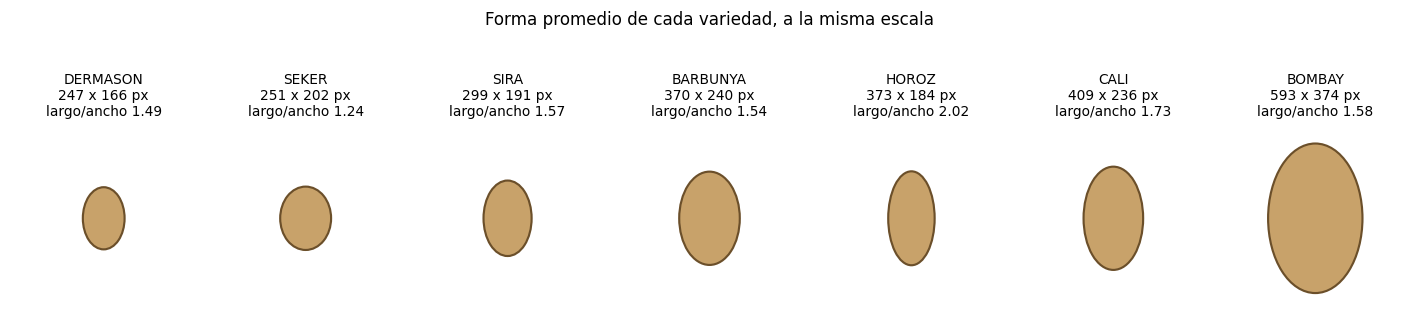

BOMBAY tiene una longitud promedio de 593 píxeles y DERMASON de 247.
Esta diferencia de tamaño puede facilitar la clasificación de BOMBAY.


In [5]:
from matplotlib.patches import Ellipse

promedios = (datos.groupby("Class")[["MajorAxisLength", "MinorAxisLength"]]
             .mean().sort_values("MajorAxisLength"))

fig, ejes = plt.subplots(1, len(promedios), figsize=(13, 3.6))
limite = promedios["MajorAxisLength"].max() * 0.62

for eje, (variedad, fila) in zip(ejes, promedios.iterrows()):
    largo = fila["MajorAxisLength"]
    ancho = fila["MinorAxisLength"]
    eje.add_patch(Ellipse((0, 0), ancho, largo, facecolor="#c8a26a",
                          edgecolor="#6b4f2a", linewidth=1.4))
    eje.set_xlim(-limite, limite)
    eje.set_ylim(-limite, limite)
    eje.set_aspect("equal")
    eje.axis("off")
    eje.set_title("{}\n{:.0f} x {:.0f} px\nlargo/ancho {:.2f}"
                  .format(variedad, largo, ancho, largo / ancho),
                  fontsize=9)

fig.suptitle("Forma promedio de cada variedad, a la misma escala",
             fontsize=11)
plt.tight_layout()
plt.show()

print("BOMBAY tiene una longitud promedio de {:.0f} píxeles y DERMASON de {:.0f}."
      .format(promedios.loc["BOMBAY", "MajorAxisLength"],
              promedios.loc["DERMASON", "MajorAxisLength"]))
print("Esta diferencia de tamaño puede facilitar la clasificación de BOMBAY.")

## 2. Separación de características y etiqueta

Las primeras 16 columnas corresponden a las características
numéricas del grano y se utilizan como variables de entrada (X).
La última columna, `Class`, corresponde a la etiqueta (y), que
indica la variedad de frijol que el algoritmo debe aprender a
clasificar.

In [6]:
X = datos.drop(columns="Class")
y = datos["Class"]

print("Características", X.shape)
print("Etiquetas      ", y.shape)
print()
print("Las 16 características son")
for nombre in X.columns:
    print("   ", nombre)

Características (13611, 16)
Etiquetas       (13611,)

Las 16 características son
    Area
    Perimeter
    MajorAxisLength
    MinorAxisLength
    AspectRatio
    Eccentricity
    ConvexArea
    EquivDiameter
    Extent
    Solidity
    Roundness
    Compactness
    ShapeFactor1
    ShapeFactor2
    ShapeFactor3
    ShapeFactor4


In [7]:
# las características tienen escalas distintas, por lo que es necesario escalarlas o estandarizarlas
resumen = X.describe().T[["mean", "std", "min", "max"]]
print(resumen.round(3))
print()
print("Area alcanza un valor máximo de", int(X["Area"].max()),
      "y Solidity de", round(X["Solidity"].max(), 3))
print("Sin estandarizar los datos, Area tendría una mayor influencia "
      "en el cálculo de distancias debido a su escala numérica.")

                      mean        std        min         max
Area             53048.285  29324.096  20420.000  254616.000
Perimeter          855.283    214.290    524.736    1985.370
MajorAxisLength    320.142     85.694    183.601     738.860
MinorAxisLength    202.271     44.970    122.513     460.198
AspectRatio          1.583      0.247      1.025       2.430
Eccentricity         0.751      0.092      0.219       0.911
ConvexArea       53768.200  29774.916  20684.000  263261.000
EquivDiameter      253.064     59.177    161.244     569.374
Extent               0.750      0.049      0.555       0.866
Solidity             0.987      0.005      0.919       0.995
Roundness            0.873      0.060      0.490       0.991
Compactness          0.800      0.062      0.641       0.987
ShapeFactor1         0.007      0.001      0.003       0.010
ShapeFactor2         0.002      0.001      0.001       0.004
ShapeFactor3         0.644      0.099      0.410       0.975
ShapeFactor4         0.9

## 3. División de datos en entrenamiento y prueba

Se reserva el 20 % de los datos para la prueba y se utiliza el parámetro
`stratify` para conservar aproximadamente la misma proporción de las
siete variedades de frijol en ambos grupos.

El artículo revisado en clase utiliza una división del 50 % para
entrenamiento y 50 % para prueba, sin mezclar los datos, en un ejemplo
de apenas 28 registros. En este ejercicio se utiliza una distribución
del 80 % y 20 %, una práctica habitual en el aprendizaje automático
que destina una mayor cantidad de datos al entrenamiento y reserva
el resto para evaluar el clasificador.

In [8]:
X_entrena, X_prueba, y_entrena, y_prueba = train_test_split(
    X, y, test_size=0.2, random_state=SEMILLA, stratify=y)

print("Entrenamiento", X_entrena.shape)
print("Prueba       ", X_prueba.shape)

Entrenamiento (10888, 16)
Prueba        (2723, 16)


## 4. Estandarización con StandardScaler

KNN clasifica los datos en función de las distancias entre ellos.
Si una característica tiene valores en miles y otra en decimales,
la primera puede influir más en el resultado, aunque no sea la
más importante. Por ello, se utiliza `StandardScaler` para llevar
las características a una escala comparable.

El escalador se ajusta **solo con los datos de entrenamiento**.
Si se ajustara con todos los datos, se produciría una fuga de
información, es decir, se utilizaría información de los datos
de prueba antes de evaluar el modelo, lo que podría generar
resultados más favorables de lo que realmente serían con datos nuevos.

In [9]:
escalador = StandardScaler()
X_entrena_esc = escalador.fit_transform(X_entrena)
X_prueba_esc = escalador.transform(X_prueba)

print("Antes de escalar, la primera fila")
print(X_entrena.iloc[0].values[:5].round(3), "...")
print()
print("Después de escalar, la misma fila")
print(X_entrena_esc[0][:5].round(3), "...")
print()
print("Media después de escalar", round(X_entrena_esc.mean(), 6))
print("Desviación estándar     ", round(X_entrena_esc.std(), 6))

Antes de escalar, la primera fila
[4.21420e+04 7.41324e+02 2.60524e+02 2.06118e+02 1.26400e+00] ...

Después de escalar, la misma fila
[-0.371 -0.531 -0.695  0.087 -1.294] ...

Media después de escalar 0.0
Desviación estándar      1.0


## 5. Cálculo manual de KNN

Antes de utilizar la librería scikit-learn, se realiza el cálculo
de forma manual con NumPy para comprender la lógica y el
funcionamiento del algoritmo.

Para clasificar un grano nuevo, se calcula la distancia euclidiana
entre este y todos los granos de entrenamiento. Las distancias
se ordenan de menor a mayor, se seleccionan los K vecinos más
cercanos y se asigna la variedad que aparece con mayor frecuencia.

La distancia euclidiana se obtiene al calcular la raíz cuadrada
de la suma de las diferencias al cuadrado entre los valores
de cada característica de los dos registros.

In [10]:
K_DEMO = 7

# seleccionar un grano del grupo de prueba
indice = 0
grano = X_prueba_esc[indice]
variedad_real = y_prueba.iloc[indice]

# cálculo de la distancia euclidiana entre el grano seleccionado
# y cada grano de entrenamiento
diferencias = X_entrena_esc - grano
distancias = np.sqrt((diferencias ** 2).sum(axis=1))

# selección de los K vecinos más cercanos
cercanos = np.argsort(distancias)[:K_DEMO]

vecinos = pd.DataFrame({
    "distancia": distancias[cercanos].round(3),
    "variedad": y_entrena.iloc[cercanos].values})
print(vecinos.to_string(index=False))
print()

votos = y_entrena.iloc[cercanos].value_counts()
print("Votos", dict(votos))
print("Predicción manual  ", votos.index[0])
print("Variedad real      ", variedad_real)

 distancia variedad
     0.193 DERMASON
     0.220 DERMASON
     0.301 DERMASON
     0.305 DERMASON
     0.307 DERMASON
     0.332 DERMASON
     0.345     SIRA

Votos {'DERMASON': np.int64(6), 'SIRA': np.int64(1)}
Predicción manual   DERMASON
Variedad real       DERMASON


In [11]:
# comparar la predicción manual con la obtenida con scikit-learn
knn_demo = KNeighborsClassifier(n_neighbors=K_DEMO, metric="euclidean")
knn_demo.fit(X_entrena_esc, y_entrena)

print("Predicción de scikit-learn", knn_demo.predict([grano])[0])
print()
print("KNN no requiere un entrenamiento iterativo. El método fit()")
print("almacena los datos y prepara el clasificador.")
print("La mayor parte del cálculo ocurre al buscar los vecinos durante la predicción.")

Predicción de scikit-learn DERMASON

KNN no requiere un entrenamiento iterativo. El método fit()
almacena los datos y prepara el clasificador.
La mayor parte del cálculo ocurre al buscar los vecinos durante la predicción.


## 6. Selección del valor de K

K es uno de los principales parámetros del algoritmo, ya que
determina cuántos vecinos se consideran para realizar una
clasificación. Para seleccionar el valor más adecuado, se prueban
distintos valores de K con validación cruzada de cinco particiones,
sin utilizar los datos de prueba.

También se comparan los métodos de votación `uniform` y `distance`
disponibles en scikit-learn. En el primero, todos los vecinos tienen
el mismo peso en la votación, mientras que en el segundo se asigna
un mayor peso a los vecinos más cercanos.

In [12]:
valores_k = [1, 3, 5, 7, 9, 11, 15, 21, 31, 41]
resultados = []

for pesos in ["uniform", "distance"]:
    for k in valores_k:
        # el escalador se incluye dentro del pipeline para ajustarlo
        # con los datos de entrenamiento de cada partición de la
        # validación cruzada y evitar la fuga de información
        modelo = make_pipeline(
            StandardScaler(),
            KNeighborsClassifier(n_neighbors=k, weights=pesos,
                                 metric="euclidean"))
        # el parámetro n_jobs=1 ayuda a reducir el consumo de memoria
        # durante la validación cruzada
        puntaje = cross_val_score(modelo, X_entrena, y_entrena, cv=5,
                                  scoring="accuracy", n_jobs=1).mean()
        resultados.append({"k": k, "pesos": pesos, "accuracy": puntaje})

tabla = pd.DataFrame(resultados)
tabla.pivot(index="k", columns="pesos", values="accuracy").round(4)

pesos,distance,uniform
k,,
1,0.9066,0.9066
3,0.9175,0.9175
5,0.9226,0.9215
7,0.9250,0.9239
9,0.9248,0.9240
11,0.9249,0.9241
15,0.9254,0.9243
21,0.9269,0.9272
31,0.9260,0.9244


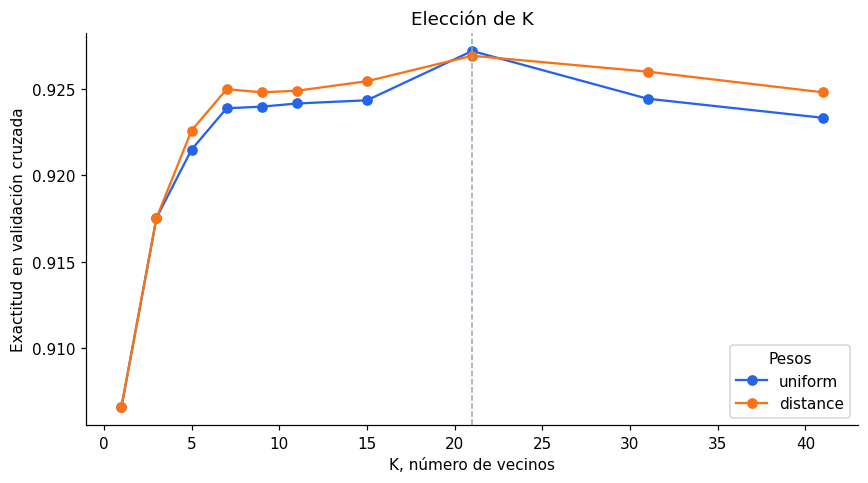

Mejor K 21 con pesos uniform y exactitud 0.9272


In [13]:
fig, eje = plt.subplots(figsize=(8, 4.5))
for pesos, color in (("uniform", "#2563eb"), ("distance", "#f97316")):
    parte = tabla[tabla["pesos"] == pesos]
    eje.plot(parte["k"], parte["accuracy"], marker="o", label=pesos,
             color=color)

mejor = tabla.loc[tabla["accuracy"].idxmax()]
eje.axvline(mejor["k"], color="#94a3b8", linestyle="--", linewidth=1)
eje.set_xlabel("K, número de vecinos")
eje.set_ylabel("Exactitud en validación cruzada")
eje.set_title("Elección de K")
eje.legend(title="Pesos")
plt.tight_layout()
plt.show()

MEJOR_K = int(mejor["k"])
MEJORES_PESOS = mejor["pesos"]
print("Mejor K", MEJOR_K, "con pesos", MEJORES_PESOS,
      "y exactitud", round(mejor["accuracy"], 4))

## 7. Entrenar y evaluar el modelo final

In [14]:
knn = KNeighborsClassifier(n_neighbors=MEJOR_K, weights=MEJORES_PESOS,
                           metric="euclidean")
knn.fit(X_entrena_esc, y_entrena)
predicciones = knn.predict(X_prueba_esc)

exactitud = accuracy_score(y_prueba, predicciones)
print("Exactitud en el conjunto de prueba", round(exactitud, 4))
print()
print("Al clasificar al azar, con la misma probabilidad para cada variedad,")
print("la exactitud esperada sería del", round(100 / 7, 1), "por ciento.")

Exactitud en el conjunto de prueba 0.9188

Al clasificar al azar, con la misma probabilidad para cada variedad,
la exactitud esperada sería del 14.3 por ciento.


In [15]:
print(classification_report(y_prueba, predicciones, digits=3))

              precision    recall  f1-score   support

    BARBUNYA      0.971     0.872     0.918       265
      BOMBAY      1.000     1.000     1.000       104
        CALI      0.918     0.960     0.939       326
    DERMASON      0.916     0.908     0.912       709
       HOROZ      0.958     0.946     0.952       386
       SEKER      0.936     0.943     0.940       406
        SIRA      0.845     0.877     0.860       527

    accuracy                          0.919      2723
   macro avg      0.935     0.929     0.932      2723
weighted avg      0.920     0.919     0.919      2723



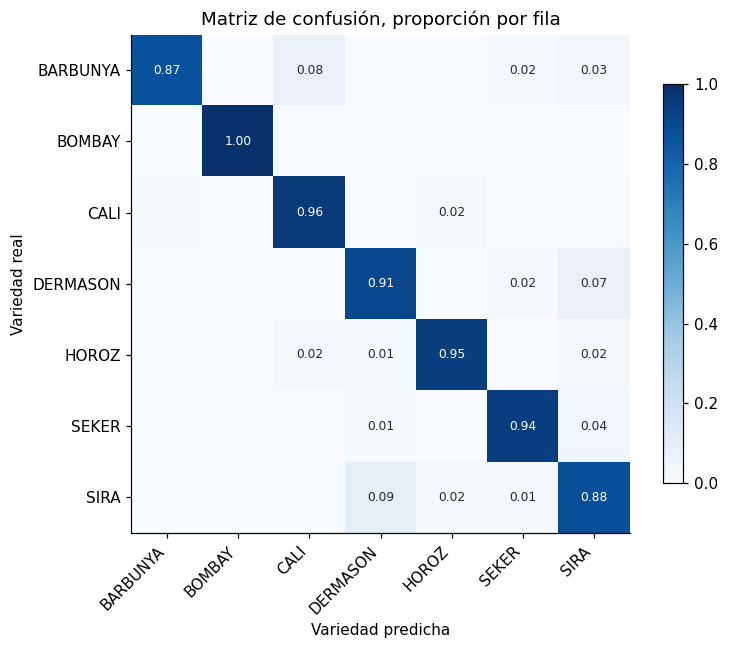

In [16]:
clases = sorted(y.unique())
matriz = confusion_matrix(y_prueba, predicciones, labels=clases)
matriz_pct = matriz / matriz.sum(axis=1, keepdims=True)

fig, eje = plt.subplots(figsize=(7.5, 6))
imagen = eje.imshow(matriz_pct, cmap="Blues", vmin=0, vmax=1)
eje.set_xticks(range(len(clases)), clases, rotation=45, ha="right")
eje.set_yticks(range(len(clases)), clases)
eje.set_xlabel("Variedad predicha")
eje.set_ylabel("Variedad real")
eje.set_title("Matriz de confusión, proporción por fila")

for f in range(len(clases)):
    for c in range(len(clases)):
        valor = matriz_pct[f, c]
        if valor > 0.01:
            eje.text(c, f, format(valor, ".2f"), ha="center", va="center",
                     color="white" if valor > 0.5 else "#1e293b", fontsize=8)

fig.colorbar(imagen, ax=eje, shrink=0.8)
plt.tight_layout()
plt.show()

In [17]:
# identificar las variedades que el modelo confunde con mayor frecuencia
confusiones = [(clases[f], clases[c], matriz_pct[f, c])
               for f in range(len(clases))
               for c in range(len(clases)) if f != c]
confusiones.sort(key=lambda t: -t[2])

print("Las variedades que más se confunden")
for real, predicha, proporcion in confusiones[:5]:
    print("   {:9} se predijo como {:9} en el {:.1f} por ciento de los casos"
          .format(real, predicha, proporcion * 100))

Las variedades que más se confunden
   SIRA      se predijo como DERMASON  en el 9.1 por ciento de los casos
   BARBUNYA  se predijo como CALI      en el 7.5 por ciento de los casos
   DERMASON  se predijo como SIRA      en el 7.2 por ciento de los casos
   SEKER     se predijo como SIRA      en el 3.7 por ciento de los casos
   BARBUNYA  se predijo como SIRA      en el 3.4 por ciento de los casos


## 8. Comprobaciones

Se realizan dos comparaciones para analizar cómo la estandarización
de los datos y la métrica de distancia afectan la exactitud del
clasificador.

In [18]:
# evaluación de la exactitud del modelo sin estandarizar los datos
knn_crudo = KNeighborsClassifier(n_neighbors=MEJOR_K, weights=MEJORES_PESOS)
knn_crudo.fit(X_entrena, y_entrena)
sin_escalar = accuracy_score(y_prueba, knn_crudo.predict(X_prueba))

print("Sin escalar ", round(sin_escalar, 4))
print("Con escalado", round(exactitud, 4))
print()
print("Diferencia de", round((exactitud - sin_escalar) * 100, 1),
      "puntos porcentuales.")
print("Esto demuestra la importancia de estandarizar los datos en este ejercicio.")

Sin escalar  0.6919
Con escalado 0.9188

Diferencia de 22.7 puntos porcentuales.
Esto demuestra la importancia de estandarizar los datos en este ejercicio.


In [19]:
# comparación de las distancias euclidiana y Manhattan
for metrica in ["euclidean", "manhattan"]:
    modelo = KNeighborsClassifier(n_neighbors=MEJOR_K, weights=MEJORES_PESOS,
                                  metric=metrica)
    modelo.fit(X_entrena_esc, y_entrena)
    print(metrica, round(accuracy_score(y_prueba, modelo.predict(X_prueba_esc)), 4))

euclidean 0.9188
manhattan 0.9159


### Estandarización de las 16 características

El artículo revisado en clase estandariza únicamente las columnas
de tipo `float64` con la siguiente instrucción.

```python
float_cols = X_train.select_dtypes(include=['float64']).columns
```

En el dataset del artículo, este procedimiento es razonable porque
las demás columnas contienen valores binarios (0 y 1), que ya se
encuentran en una escala reducida.

No obstante, aplicar esta instrucción al Dry Bean Dataset dejaría
fuera del escalado las características `Area` y `ConvexArea`,
almacenadas como números enteros. Estas columnas contienen valores
de gran magnitud, que superan los 250,000. Por esta razón, se
estandarizan las 16 características para evitar que las diferencias
de escala afecten el cálculo de las distancias.

In [20]:
# comprobar cuántos puntos porcentuales de exactitud costaría escalar
# únicamente las columnas float64 en lugar de las 16 características
columnas_float = X_entrena.select_dtypes(include=["float64"]).columns
fuera = [c for c in X_entrena.columns if c not in columnas_float]

print("Columnas que quedarían sin escalar:", fuera)
for c in fuera:
    print("   {:12} va de {:,} a {:,}".format(c, int(X[c].min()), int(X[c].max())))
print()

def exactitud_escalando(columnas):
    entrena, prueba = X_entrena.copy(), X_prueba.copy()
    aparte = StandardScaler()
    entrena[columnas] = aparte.fit_transform(entrena[columnas])
    prueba[columnas] = aparte.transform(prueba[columnas])
    modelo = KNeighborsClassifier(n_neighbors=MEJOR_K,
                                  weights=MEJORES_PESOS).fit(entrena, y_entrena)
    return accuracy_score(y_prueba, modelo.predict(prueba))

solo_float = exactitud_escalando(list(columnas_float))
todas = exactitud_escalando(list(X_entrena.columns))

print("Escalando solo las float64, como el artículo", round(solo_float, 4))
print("Escalando las 16 características          ", round(todas, 4))
print()
print("Diferencia de", round((todas - solo_float) * 100, 1), "puntos porcentuales.")
print("Es importante adaptar el preprocesamiento a las características "
      "del dataset antes de aplicar un procedimiento de referencia.")

Columnas que quedarían sin escalar: ['Area', 'ConvexArea']
   Area         va de 20,420 a 254,616
   ConvexArea   va de 20,684 a 263,261

Escalando solo las float64, como el artículo 0.6647
Escalando las 16 características           0.9188

Diferencia de 25.4 puntos porcentuales.
Es importante adaptar el preprocesamiento a las características del dataset antes de aplicar un procedimiento de referencia.


## 9. Predecir un grano nuevo

In [21]:
# predecir la variedad de un grano de prueba y comparar
# la predicción con su etiqueta real
posicion = 100
grano_nuevo = X_prueba.iloc[[posicion]]
real = y_prueba.iloc[posicion]

grano_escalado = escalador.transform(grano_nuevo)
prediccion = knn.predict(grano_escalado)[0]
probabilidades = pd.Series(knn.predict_proba(grano_escalado)[0],
                           index=knn.classes_).sort_values(ascending=False)

print("Medidas del grano")
print(grano_nuevo.T.iloc[:6].to_string(header=False))
print()
print("Variedad predicha", prediccion)
print("Variedad real    ", real)
print()
print("Proporción de votos de los vecinos")
print(probabilidades[probabilidades > 0].round(3).to_string())

Medidas del grano
Area             38848.000000
Perimeter          709.386000
MajorAxisLength    245.782402
MinorAxisLength    201.947377
AspectRatio          1.217062
Eccentricity         0.569991

Variedad predicha SEKER
Variedad real     SEKER

Proporción de votos de los vecinos
SEKER    1.0


## Conclusiones

El algoritmo KNN obtuvo buenos resultados en este problema de
clasificación, con una exactitud del 91.88 % en los datos de prueba.
Esto demuestra que las siete variedades de frijol se pueden distinguir
a partir de sus características de forma y tamaño, sin necesidad de
utilizar directamente las imágenes.

Uno de los aspectos más importantes del ejercicio fue la estandarización
de los datos. Las características presentan escalas muy distintas, dado
que `Area` alcanza valores de miles, mientras que `Solidity` se mantiene
entre cero y uno. Por ende, sin estandarizar los datos, las características
de mayor magnitud adquieren un peso excesivo en el cálculo de las
distancias euclidianas.

Por otra parte, KNN no requiere un entrenamiento iterativo. El método
`fit()` almacena los datos de entrenamiento y prepara el clasificador.
La mayor parte del trabajo computacional ocurre durante la predicción,
cuando se buscan los vecinos más cercanos de un nuevo registro.
De este modo, su preparación es rápida, pero el costo computacional
de las predicciones aumenta con la cantidad de datos.

Por último, la validación cruzada permitió seleccionar K = 21 como
el mejor valor entre los evaluados, con una exactitud promedio del 92.72 %.
En cambio, al omitir la estandarización, la exactitud en los datos de
prueba disminuyó al 69.19 %. Estos resultados muestran que, en este
ejercicio, la estandarización de los datos tuvo mayor importancia
que la selección de un valor específico de K dentro del rango intermedio.